In [3]:
import numpy as np
from scipy.stats import multivariate_normal as mvn
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, Image

### Funkcje pomocnicze

In [ ]:
DATA_PATH = "zad1_files/"

def plot_points(points):
    x = points[:, 0]
    y = points[:, 1]

    plt.scatter(x, y, s=5)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.xlim(0, 100)
    plt.ylim(0, 100)
    plt.show()

def generate_uniform_points(n, l, h):
    return np.random.uniform(low=l, high=h, size=(n, 2))

def generate_normal_points(n, mu, Sigma):
    return mvn.rvs(mu, Sigma, size=n)

def generate_cluster_points(n, m, l, h):
    cluster_centers = np.random.uniform(low=l, high=h, size=(m, 2))

    clusters = []
    for center in cluster_centers:
        clusters.append(np.random.normal(loc=center, scale=1, size=(n, 2)))

    return np.random.permutation(np.concatenate(clusters))

def save(points, name):
    np.save(f"{DATA_PATH}{name}.npy", points)

def load(name):
    return np.load(f"{DATA_PATH}{name}.npy")

def plot_result(energy, temperature):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = len(energy)
    x = [i for i in range(epochs)]

    axes[0].plot(x, energy)
    axes[0].set_title("Wykres energii")
    axes[0].set_xlabel("Kroki")
    axes[0].set_ylabel("Energia")

    axes[1].plot(x, temperature)
    axes[1].set_title("Wykres temperatury")
    axes[1].set_xlabel("Kroki")
    axes[1].set_ylabel("Temperatura")

    plt.show()

def plot_path(points, name):
    x = points[:, 0]
    y = points[:, 1]

    plt.scatter(x, y, c='black', s=10)
    plt.plot(x, y, c='blue', lw=1)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.xlim(0, 100)
    plt.ylim(0, 100)
    plt.savefig(f"{DATA_PATH}{name}.png", dpi=300, bbox_inches='tight')
    plt.close()
    
def generate_graph_gif(steps, name):
    x = steps[0][:, 0]
    y = steps[0][:, 1]

    fig, ax = plt.subplots()
    scat = ax.scatter(x, y, c='black', s=10)
    line, = ax.plot([], [], c='blue', lw=1)
    ax.set_title("Przebieg zmiany cyklu")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)

    def update(i):
        x = steps[i][:, 0]
        y = steps[i][:, 1]

        line.set_data(x, y)
        return line,

    n = len(steps)
    ani = FuncAnimation(fig, update, frames=n, interval=50, blit=True)
    ani.save(f"{DATA_PATH}{name}.gif", writer="pillow")

    plt.close(fig)

def display_image(name):
    display(Image(filename=f"{DATA_PATH}{name}", width=600, height=500))

### Kod wyrzażania

Zmianę energii obliczam, uwzględniając wyłącznie energię z krawędzi podmienionych wierzchołków (tylko ona zostaje zmieniona po zamianie wierzchołków), co znacznie przyspiesza algorytm.

Zaimplementowane funkcję swapu, to consecutive swap (zamiana następnych wierzchołków), oraz arbitrary swap (zamiana dwóch losowych wierzchołków)

Wykorzystane funkcje temperatrury:
- wykładnicza,
- logarytmiczna,
- liniowa

In [224]:
def dist(p1, p2):
    return np.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def count_energy(permutation):
    n = len(permutation)
    return sum(dist(permutation[i - 1], permutation[i]) for i in range(1, n)) + dist(permutation[0], permutation[n - 1])

def count_delta_energy(permutation, swap):
    a, b = swap
    n = len(permutation)
    a_prev, a_next = (a - 1) % n, (a + 1) % n
    b_prev, b_next = (b - 1) % n, (b + 1) % n

    curr_energy = 0
    next_energy = 0

    if a_next == b:
        curr_energy += dist(permutation[a_prev], permutation[a])
        curr_energy += dist(permutation[a], permutation[b])
        curr_energy += dist(permutation[b], permutation[b_next])

        next_energy += dist(permutation[a_prev], permutation[b])
        next_energy += dist(permutation[a], permutation[b])
        next_energy += dist(permutation[a], permutation[b_next])
    elif b_next == a:
        curr_energy += dist(permutation[b_prev], permutation[b])
        curr_energy += dist(permutation[b], permutation[a])
        curr_energy += dist(permutation[a], permutation[a_next])

        next_energy += dist(permutation[b_prev], permutation[a])
        next_energy += dist(permutation[b], permutation[a])
        next_energy += dist(permutation[b], permutation[a_next])
    else:
        curr_energy += dist(permutation[a_prev], permutation[a])
        curr_energy += dist(permutation[a], permutation[a_next])
        curr_energy += dist(permutation[b_prev], permutation[b])
        curr_energy += dist(permutation[b], permutation[b_next]) 

        next_energy += dist(permutation[a_prev], permutation[b])
        next_energy += dist(permutation[b], permutation[a_next])
        next_energy += dist(permutation[b_prev], permutation[a])
        next_energy += dist(permutation[a], permutation[b_next]) 

    return next_energy - curr_energy

def cons_swap(n):
    num = np.random.randint(1, n)
    return num - 1, num

def arb_swap(n):
    x = np.random.choice(np.arange(1, n), size=2, replace=False)
    return x[0], x[1]

def exp_cooling(T, start_temperature, epoch, epochs):
    return 0.95 * T

def lin_cooling(T, start_temperature, epoch, epochs):
    return max(T - start_temperature / epochs, 0)

def log_cooling(T, start_temperature, epoch, epochs):
    return start_temperature / np.log(np.e + epoch + 1)

def count_p(T, deltaE):
    return np.exp(-deltaE / T)

def simulated_annealing(points, epochs, start_temperature, swap_function, cooling_function):
    E = count_energy(points)
    T = start_temperature
    n = len(points)

    steps = []
    energy = []
    temperature = []
    for epoch in range(epochs):
        if epoch % 100 == 0: steps.append(np.vstack((points, points[0])))
        temperature.append(T)
        energy.append(E)

        swap = swap_function(n)
        deltaE = count_delta_energy(points, swap)

        if deltaE < 0 or count_p(T, deltaE) > np.random.random():
            a, b = swap
            points[[a, b]] = points[[b, a]].copy()
            E += deltaE

        T = cooling_function(T, start_temperature, epoch, epochs)
        if T == 0: break

    return energy, temperature, steps

### Pierwszy zbiór - 50 punktów z rozkładu jednostajnego

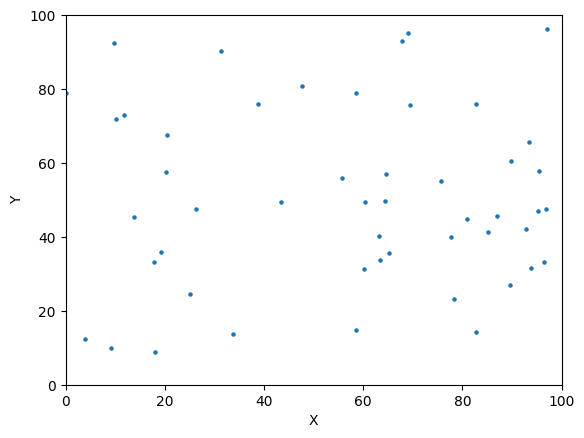

In [216]:
name = 'uniform'
uniform = load(name)

plot_points(uniform)

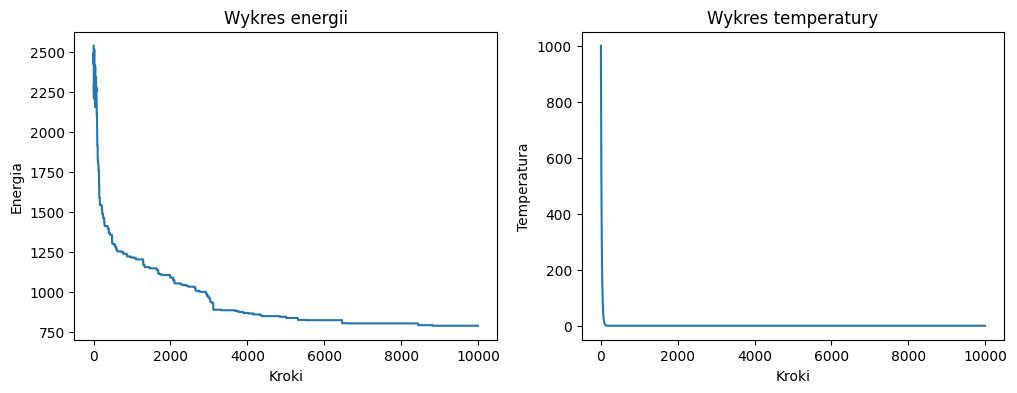

In [160]:
name = 'uniform'
uniform = load(name)

cooling_function = exp_cooling
swap_function = arb_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(uniform, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

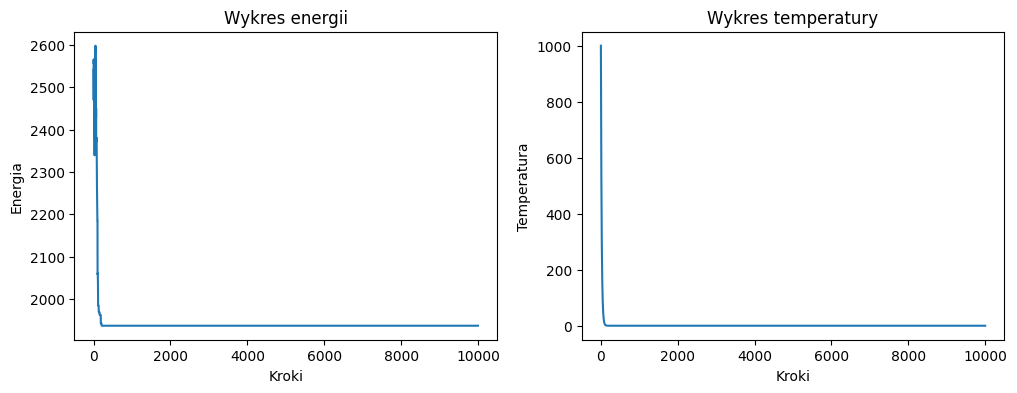

In [161]:
name = 'uniform'
uniform = load(name)

cooling_function = exp_cooling
swap_function = cons_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(uniform, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

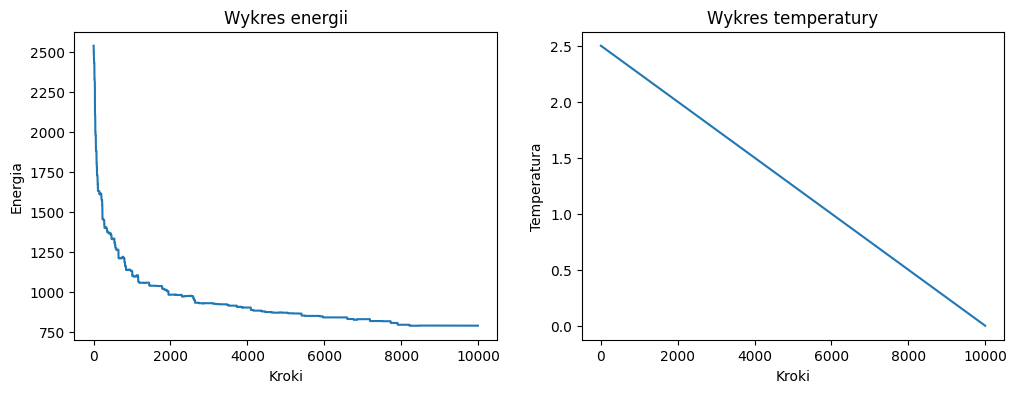

In [165]:
name = 'uniform'
uniform = load(name)

cooling_function = lin_cooling
swap_function = arb_swap
start_temperature = 2.5
epochs = 10000

energy, temperature, steps = simulated_annealing(uniform, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

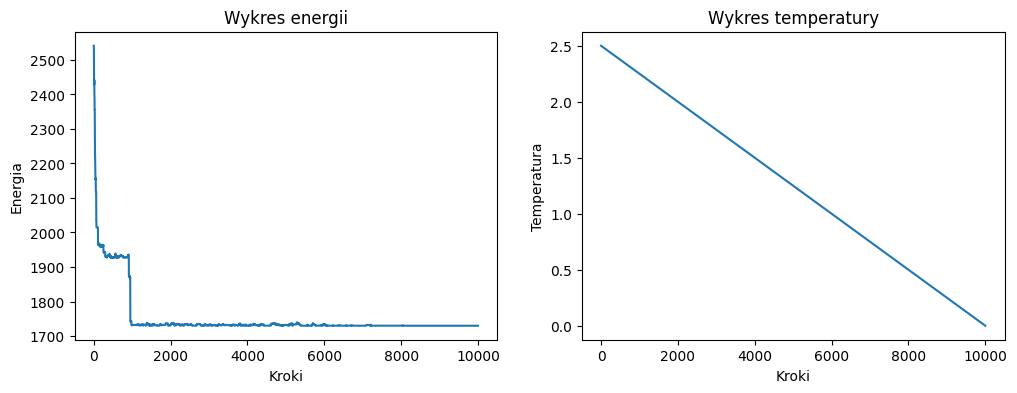

In [167]:
name = 'uniform'
uniform = load(name)

cooling_function = lin_cooling
swap_function = cons_swap
start_temperature = 2.5
epochs = 10000

energy, temperature, steps = simulated_annealing(uniform, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

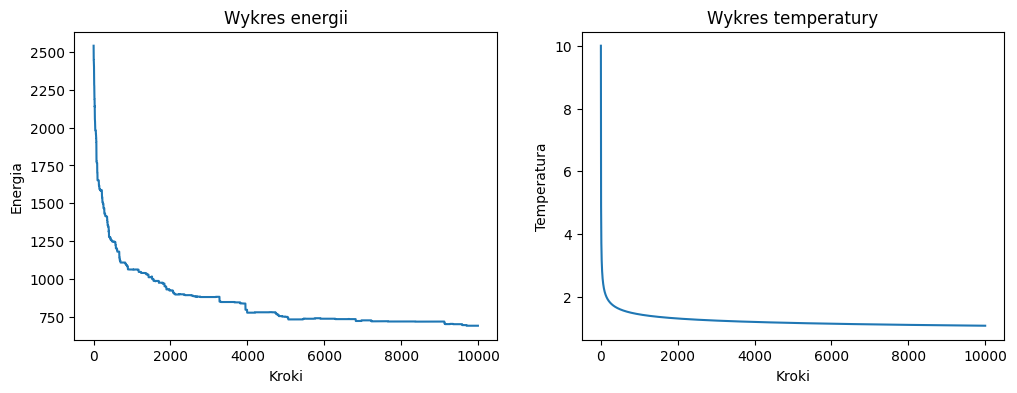

In [237]:
name = 'uniform'
uniform = load(name)

cooling_function = log_cooling
swap_function = arb_swap
start_temperature = 10
epochs = 10000

energy, temperature, steps = simulated_annealing(uniform, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

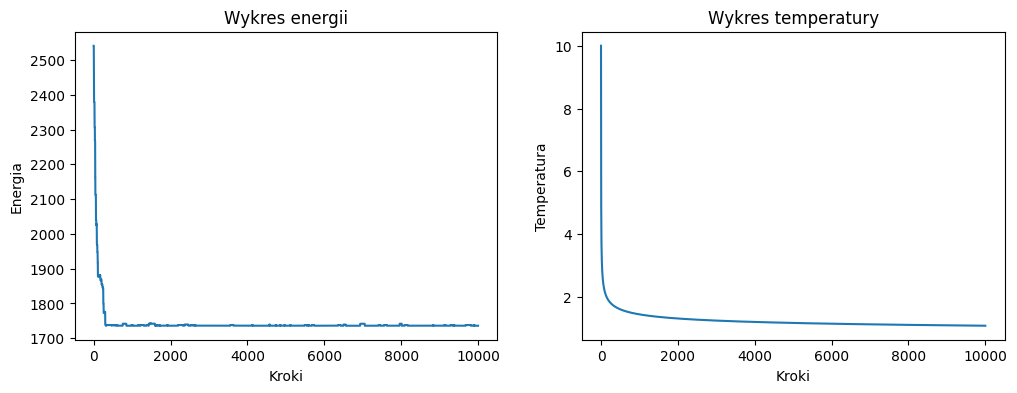

In [171]:
name = 'uniform'
uniform = load(name)

cooling_function = log_cooling
swap_function = cons_swap
start_temperature = 10
epochs = 10000

energy, temperature, steps = simulated_annealing(uniform, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

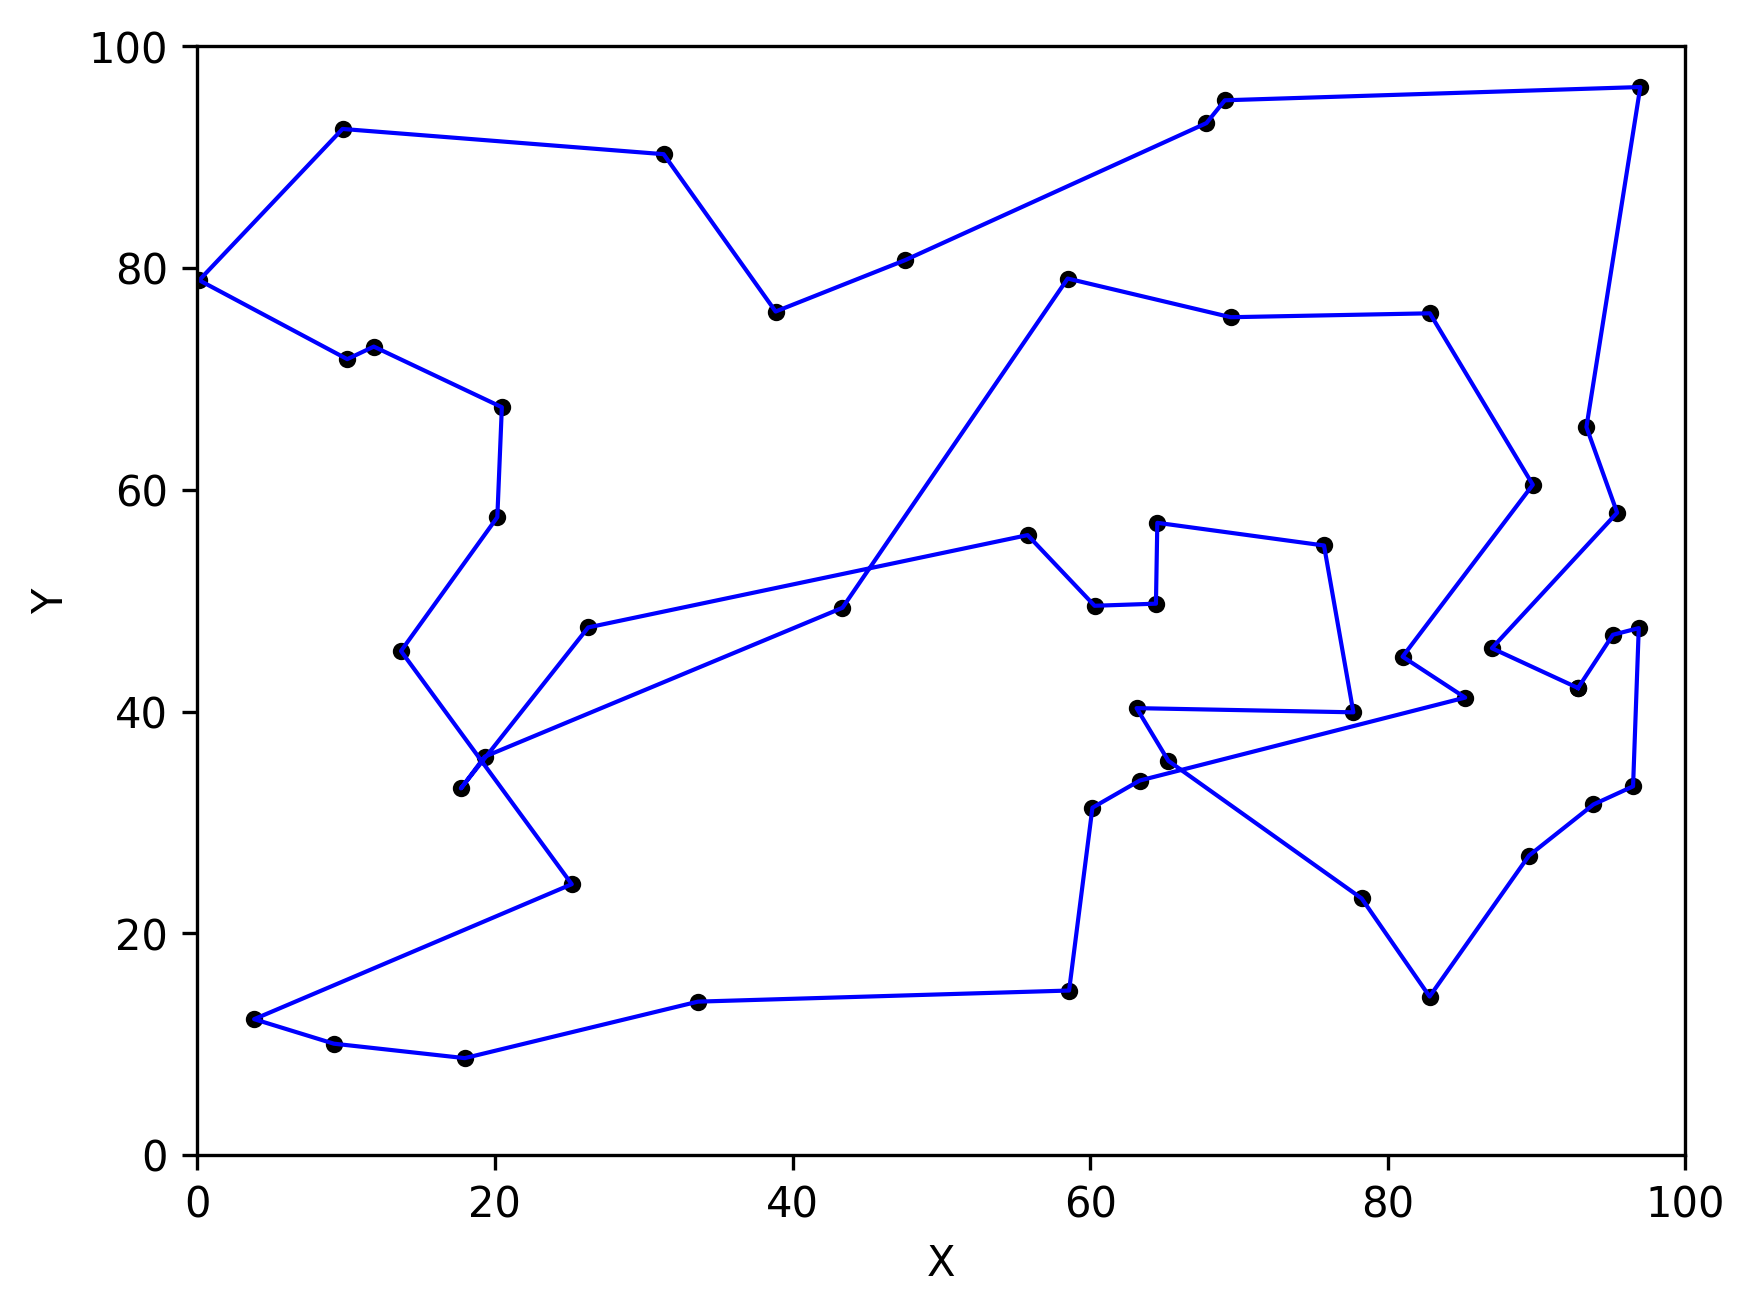

In [242]:
display_image("uniform.png")

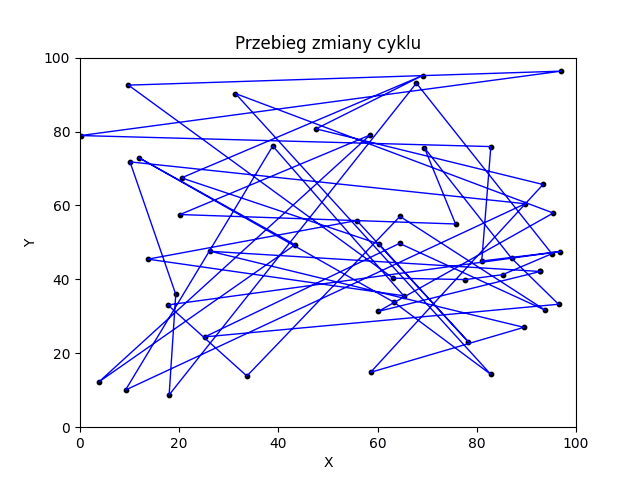

In [244]:
display_image("uniform.gif")

### Drugi zbiór - 9 klastrów po 5 punktów

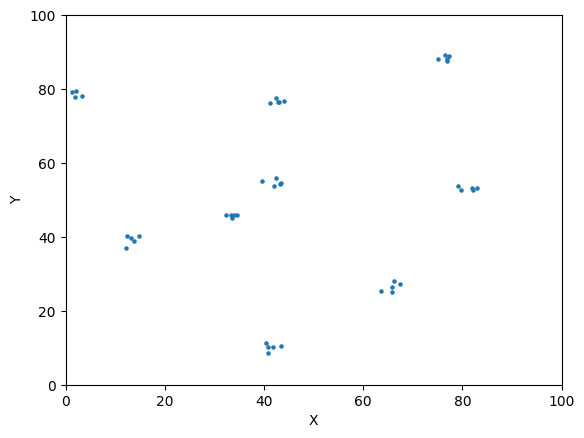

In [245]:
name = 'clusters'
clusters = load(name)

plot_points(clusters)

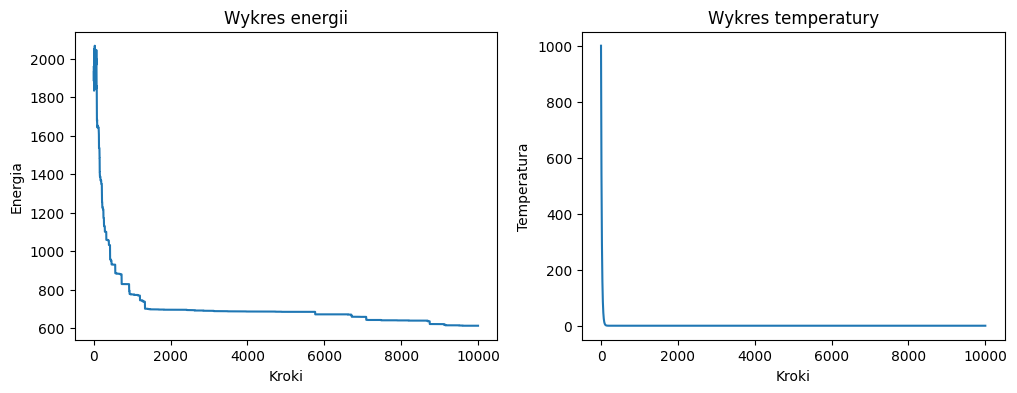

In [322]:
name = 'clusters'
clusters = load(name)

cooling_function = exp_cooling
swap_function = arb_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(clusters, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

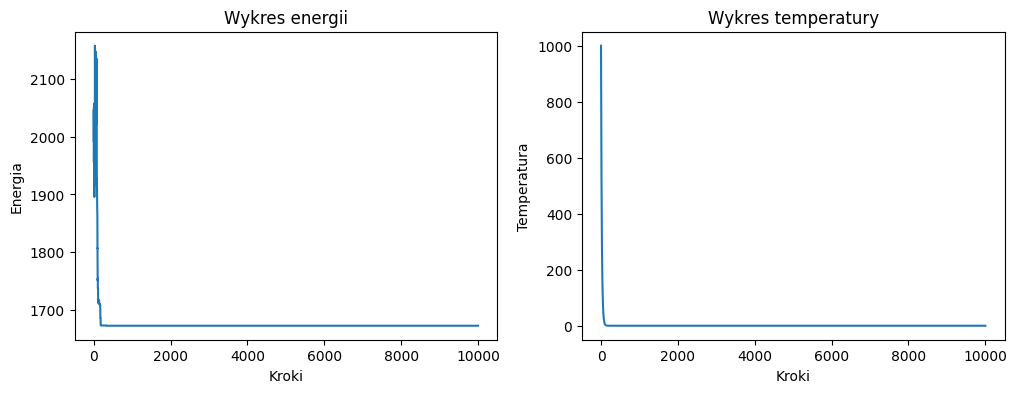

In [251]:
name = 'clusters'
clusters = load(name)

cooling_function = exp_cooling
swap_function = cons_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(clusters, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

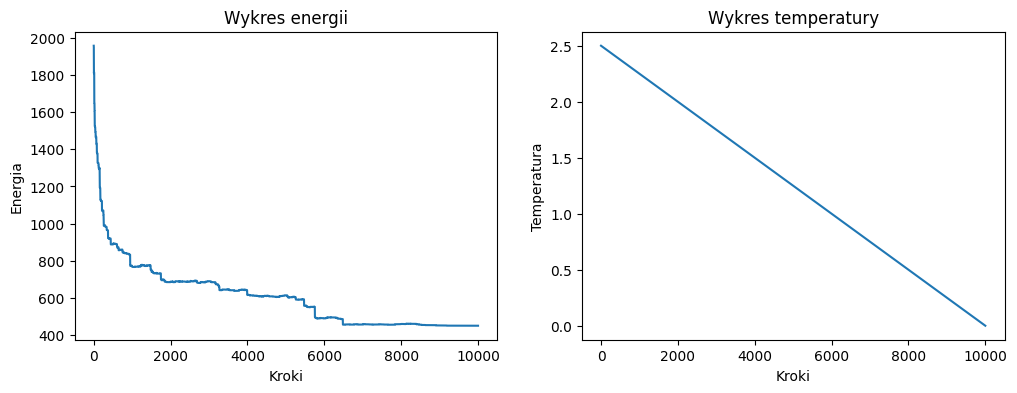

In [300]:
name = 'clusters'
clusters = load(name)

cooling_function = lin_cooling
swap_function = arb_swap
start_temperature = 2.5
epochs = 10000

energy, temperature, steps = simulated_annealing(clusters, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

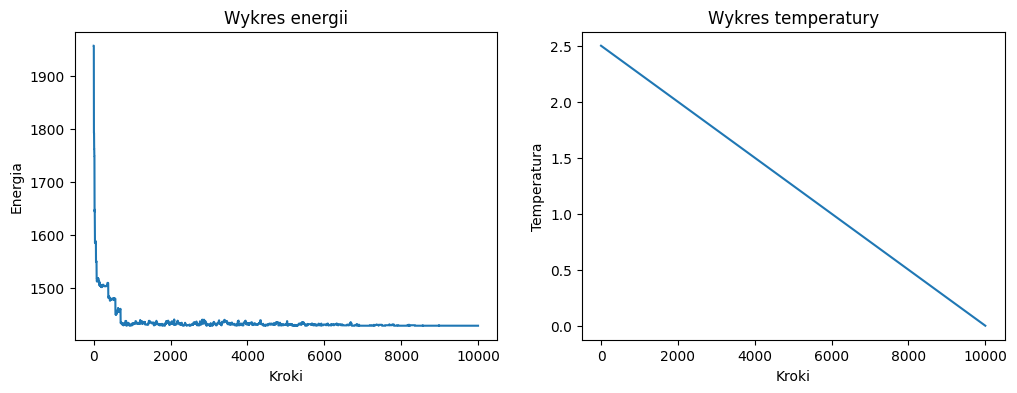

In [259]:
name = 'clusters'
clusters = load(name)

cooling_function = lin_cooling
swap_function = cons_swap
start_temperature = 2.5
epochs = 10000

energy, temperature, steps = simulated_annealing(clusters, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

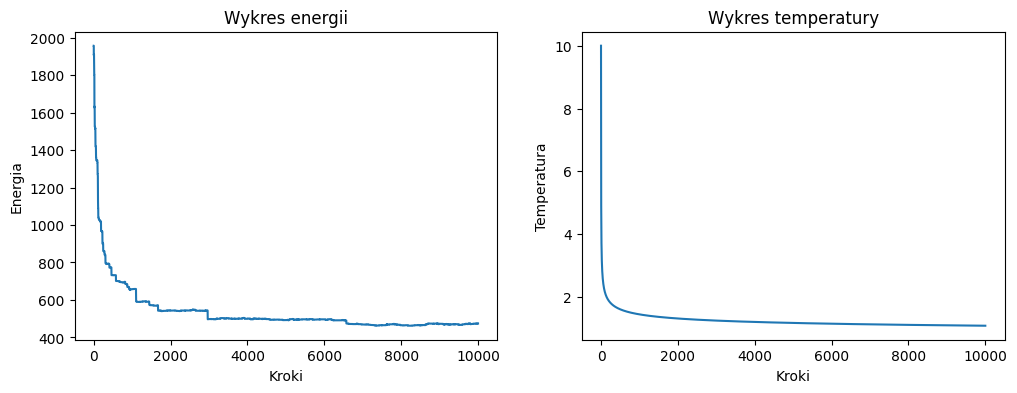

In [280]:
name = 'clusters'
clusters = load(name)

cooling_function = log_cooling
swap_function = arb_swap
start_temperature = 10
epochs = 10000

energy, temperature, steps = simulated_annealing(clusters, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

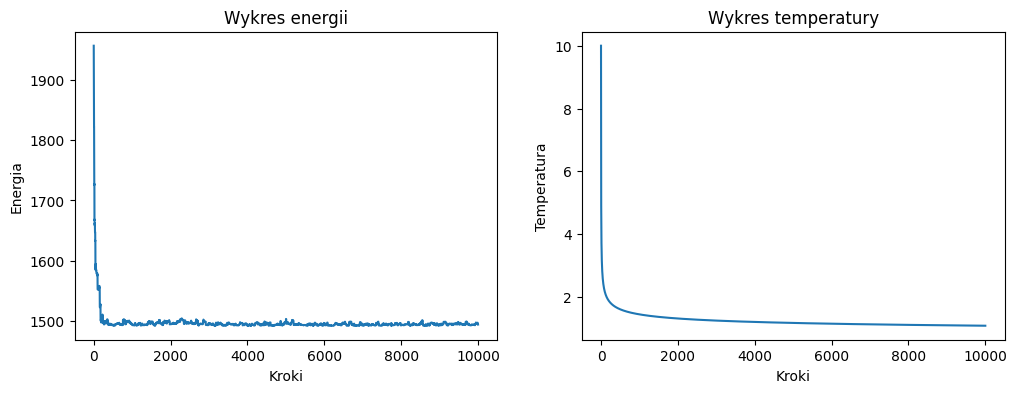

In [266]:
name = 'clusters'
clusters = load(name)

cooling_function = log_cooling
swap_function = cons_swap
start_temperature = 10
epochs = 10000

energy, temperature, steps = simulated_annealing(clusters, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

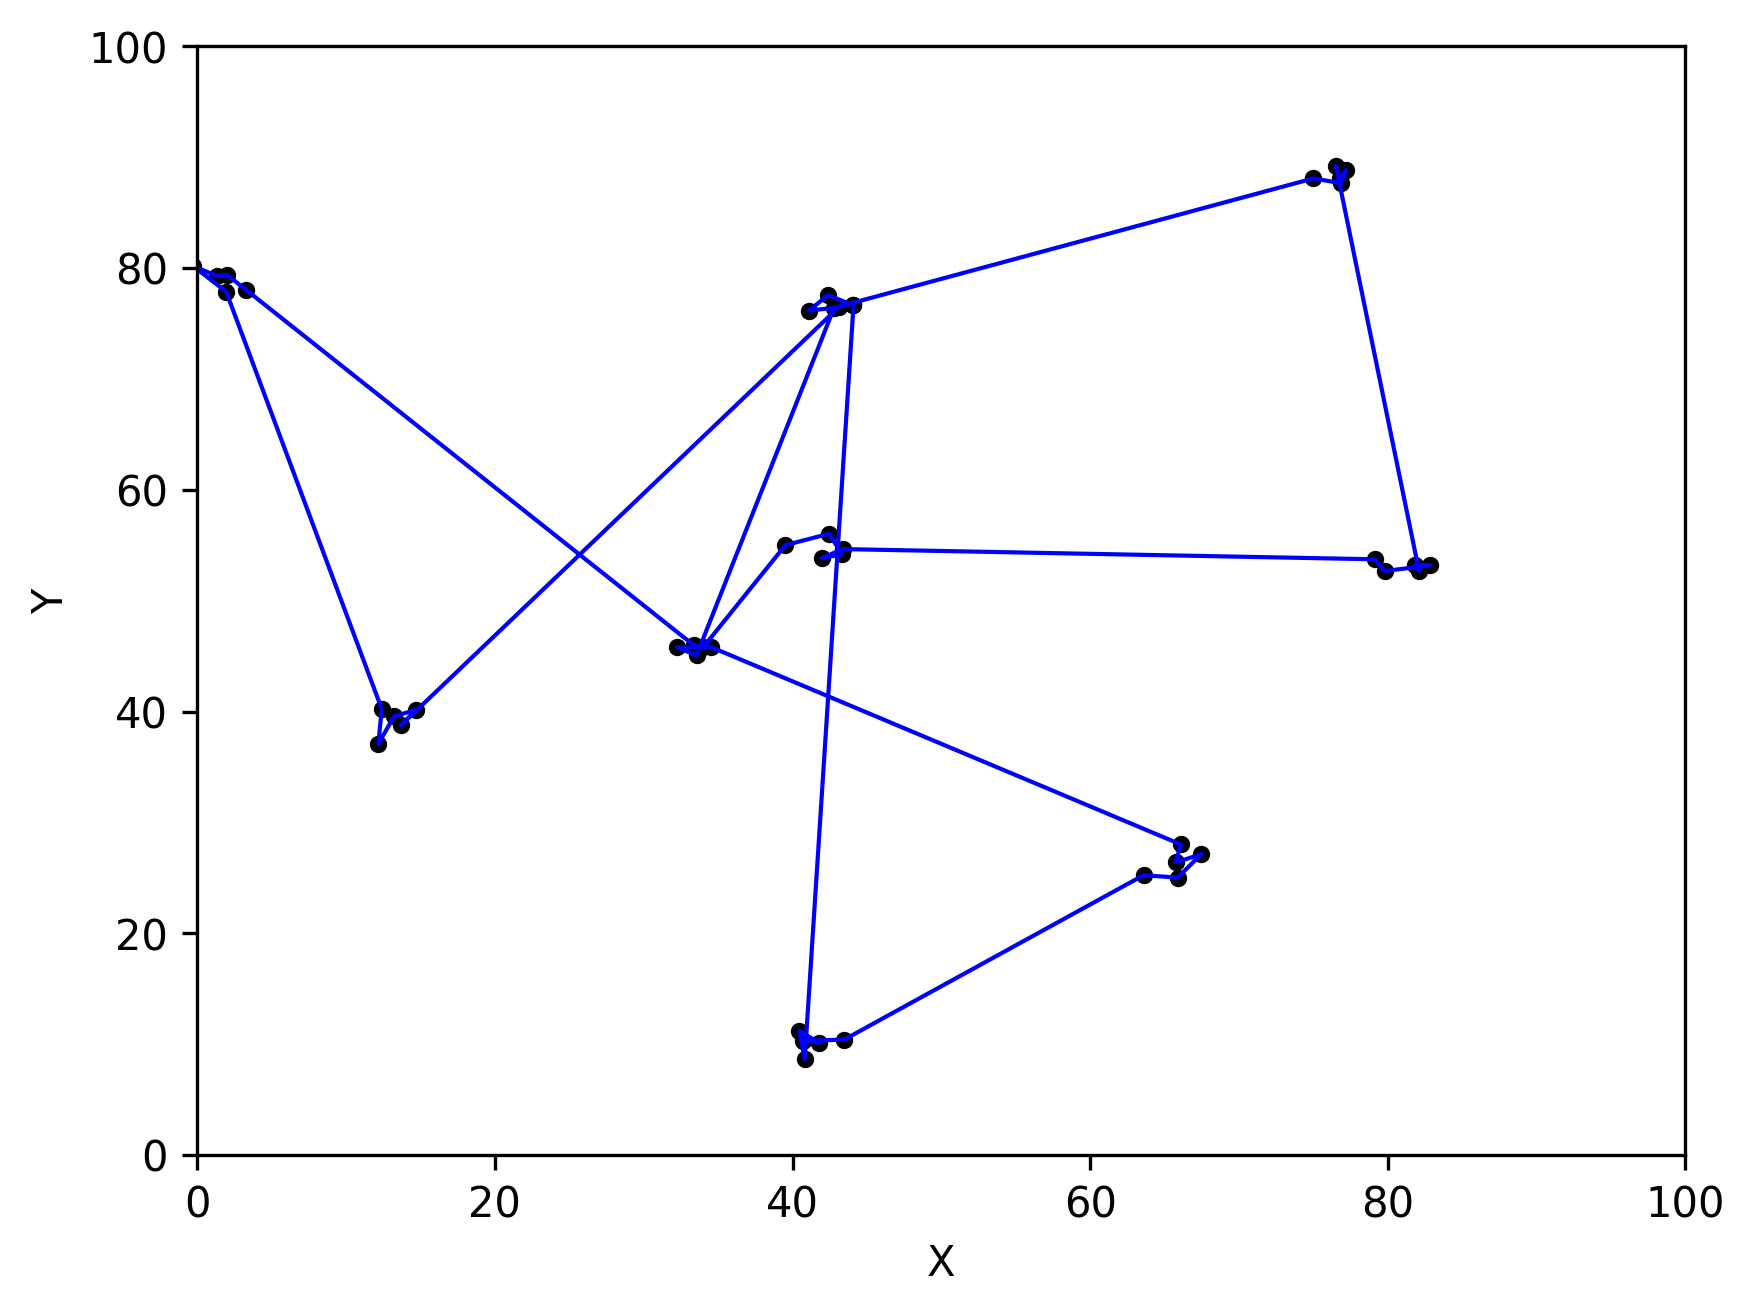

In [283]:
display_image('clusters.png')

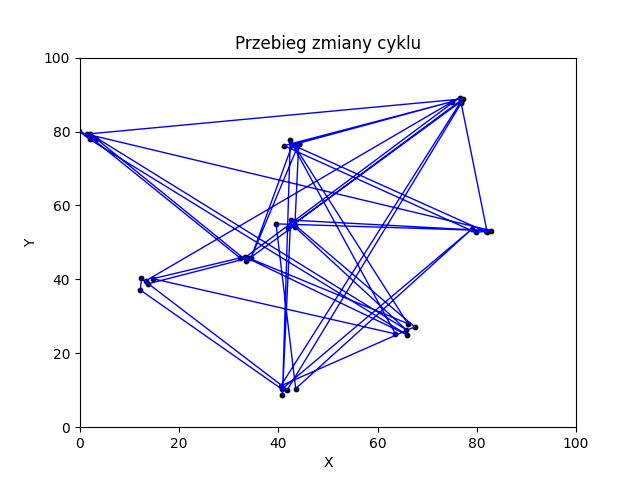

In [284]:
display_image('clusters.gif')

### Trzeci zbiór - 50 punktów z rozkładu normalnego, zmienne niezależne

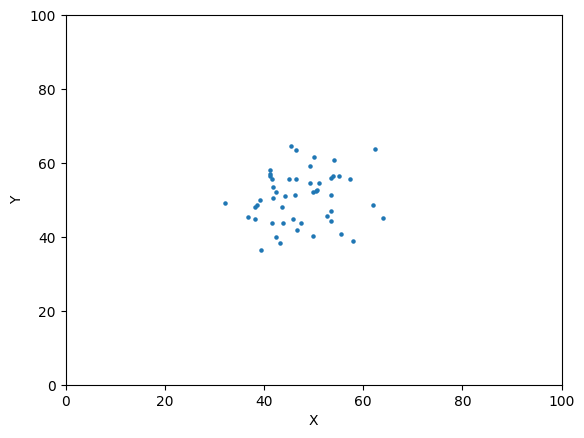

In [287]:
name = 'normal1'
normal1 = load(name)

plot_points(normal1)

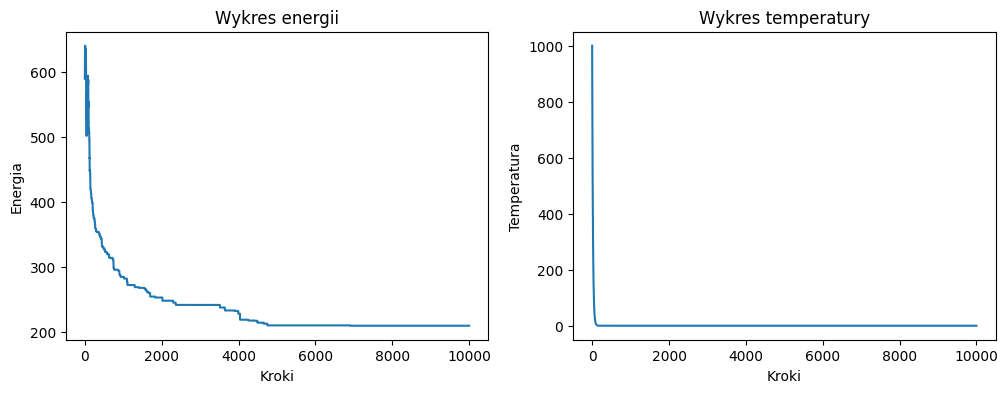

In [291]:
name = 'normal1'
normal1 = load(name)

cooling_function = exp_cooling
swap_function = arb_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(normal1, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

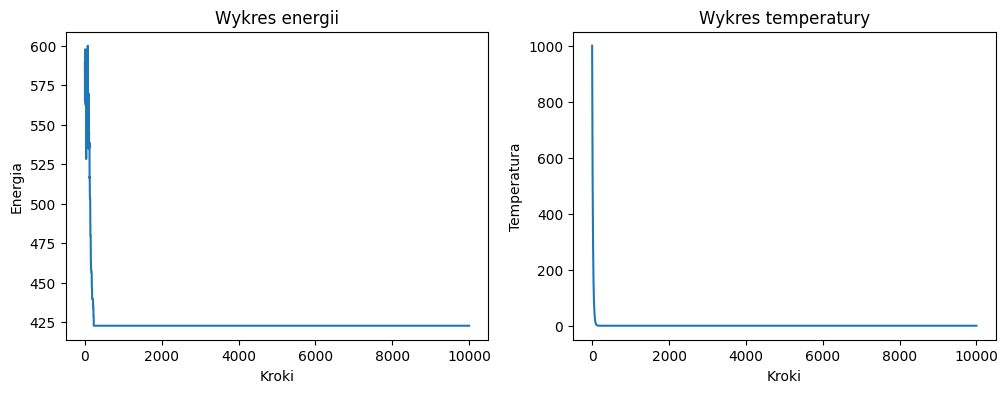

In [294]:
name = 'normal1'
normal1 = load(name)

cooling_function = exp_cooling
swap_function = cons_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(normal1, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

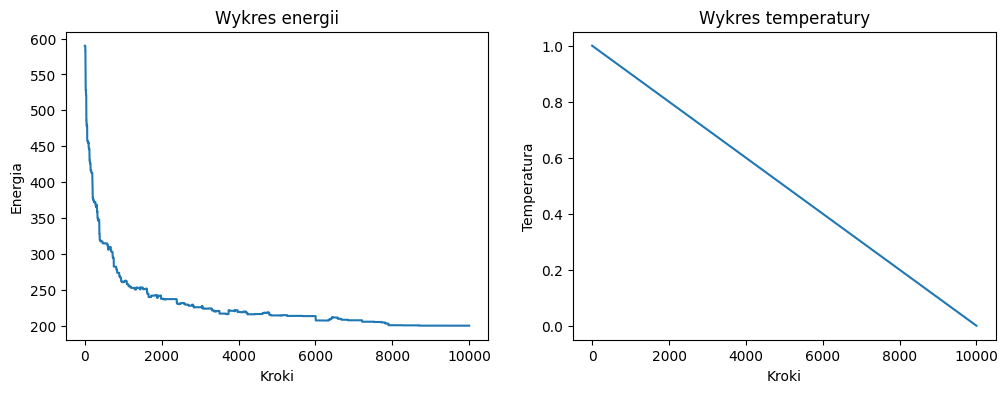

In [329]:
name = 'normal1'
normal1 = load(name)

cooling_function = lin_cooling
swap_function = arb_swap
start_temperature = 1
epochs = 10000

energy, temperature, steps = simulated_annealing(normal1, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

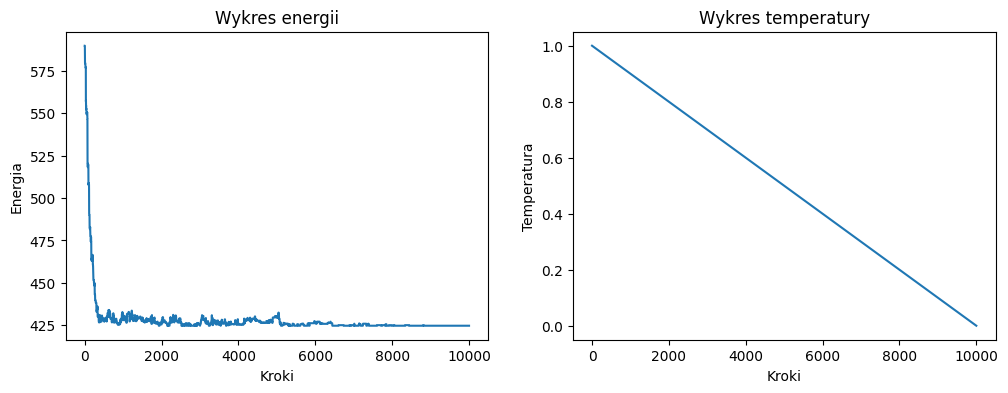

In [330]:
name = 'normal1'
normal1 = load(name)

cooling_function = lin_cooling
swap_function = cons_swap
start_temperature = 1
epochs = 10000

energy, temperature, steps = simulated_annealing(normal1, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

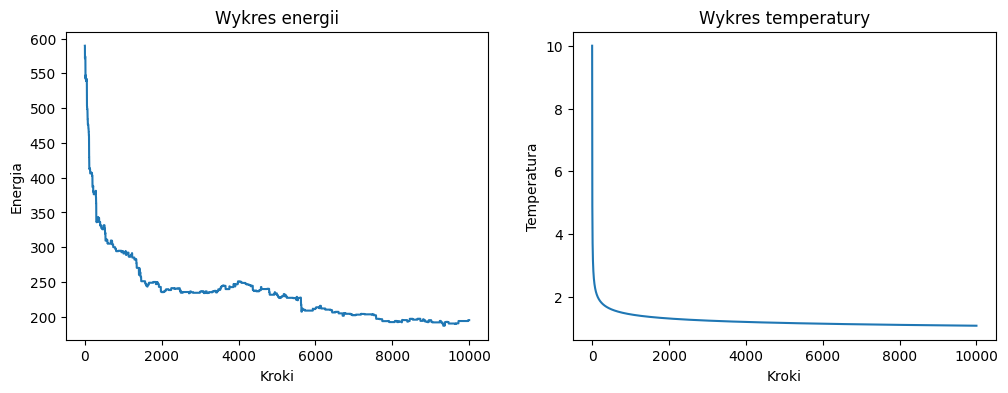

In [336]:
name = 'normal1'
normal1 = load(name)

cooling_function = log_cooling
swap_function = arb_swap
start_temperature = 10
epochs = 10000

energy, temperature, steps = simulated_annealing(normal1, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

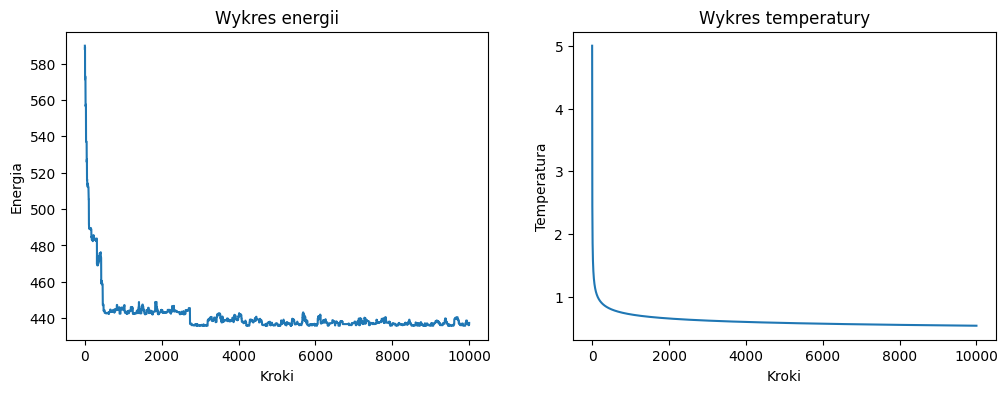

In [341]:
name = 'normal1'
normal1 = load(name)

cooling_function = log_cooling
swap_function = cons_swap
start_temperature = 5
epochs = 10000

energy, temperature, steps = simulated_annealing(normal1, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

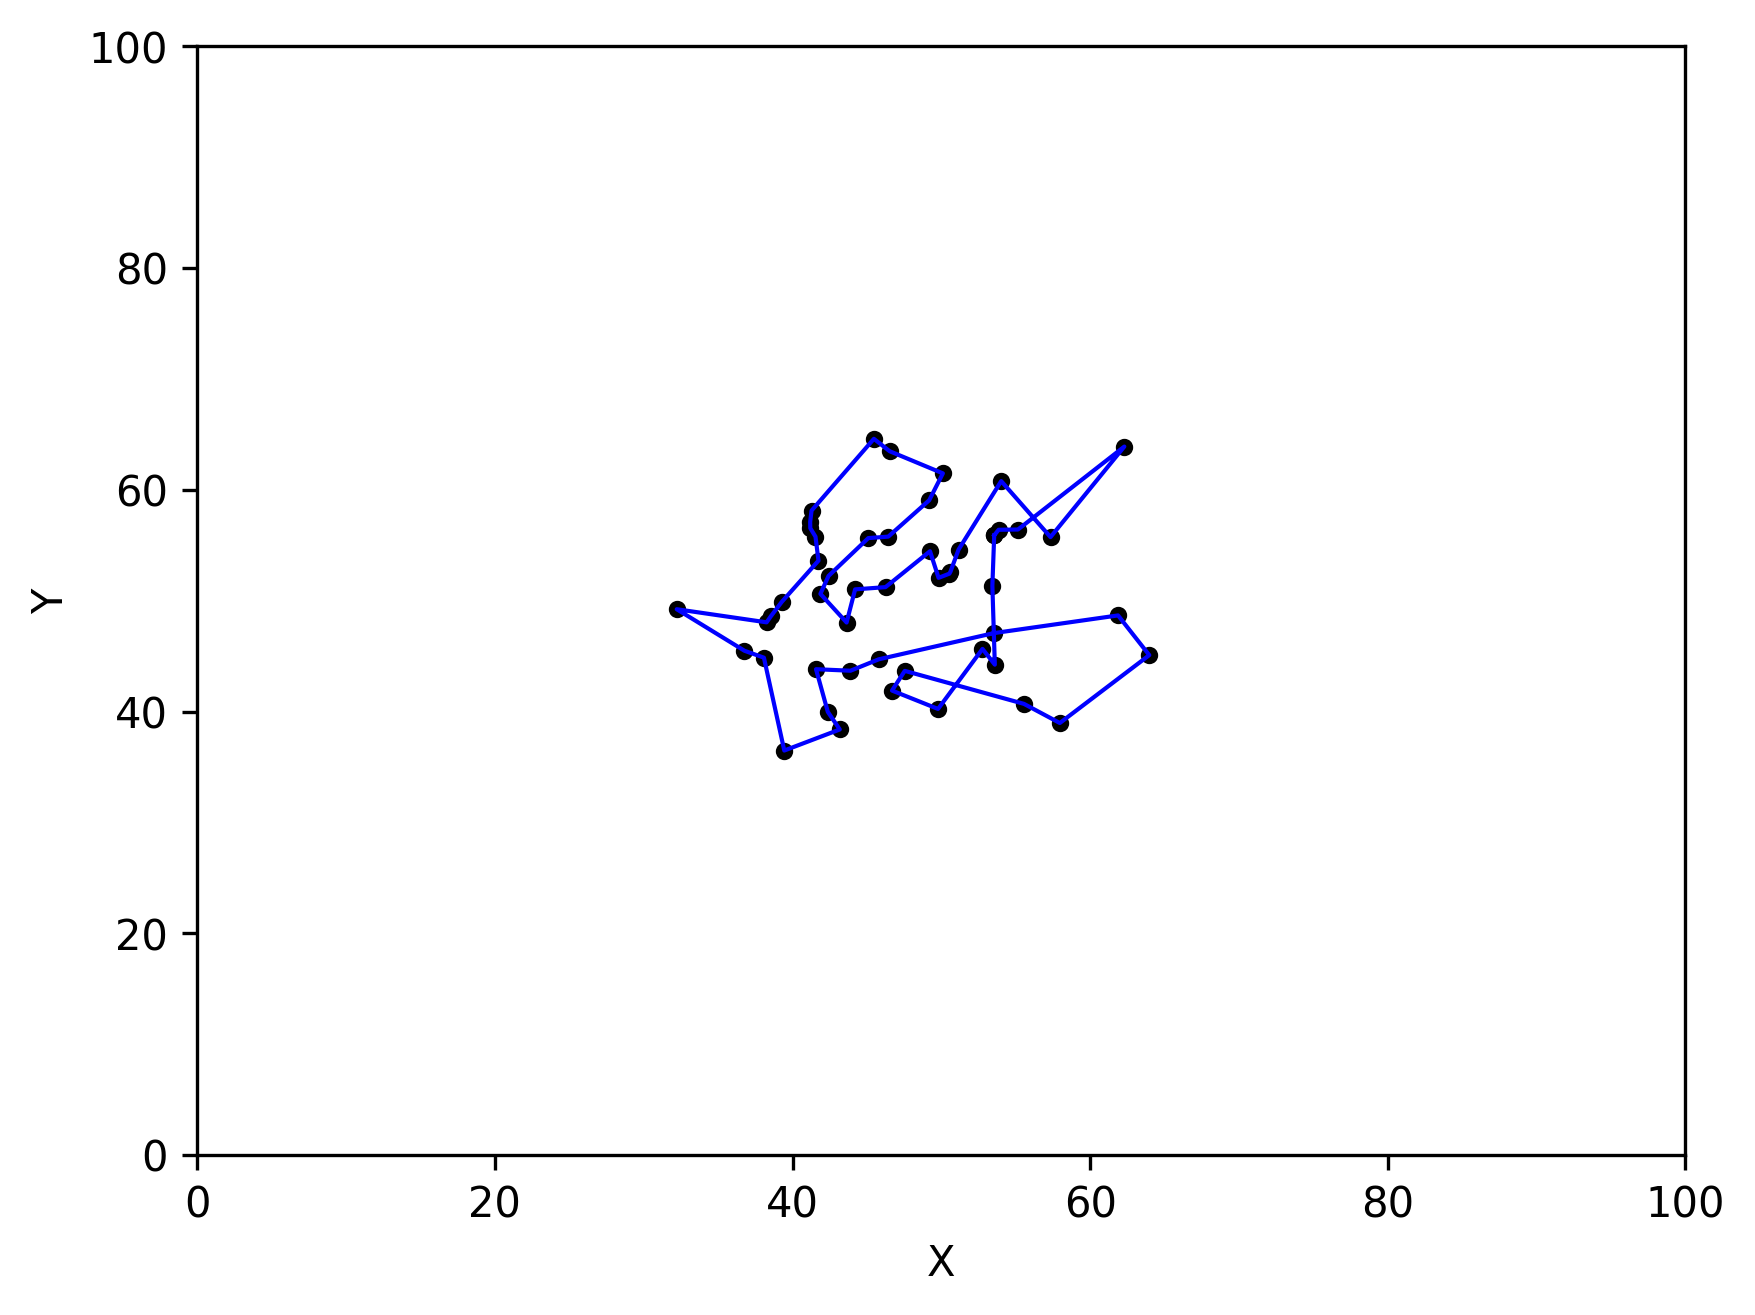

In [342]:
display_image('normal1.png')

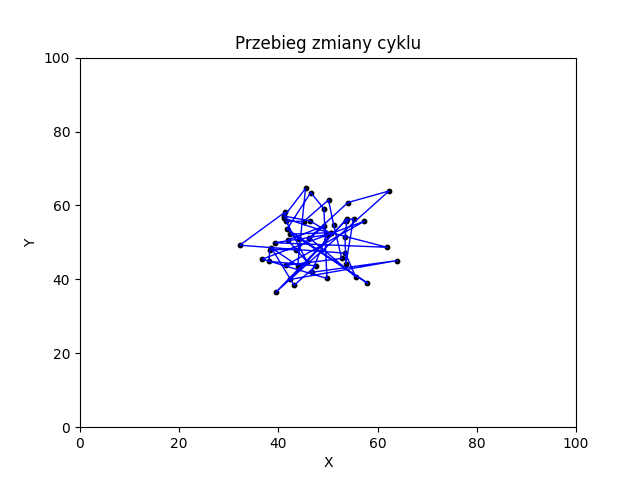

In [343]:
display_image('normal1.gif')

### Czwarty zbiór - 40 punktów z rozkładu normalnego, zmienne zależne

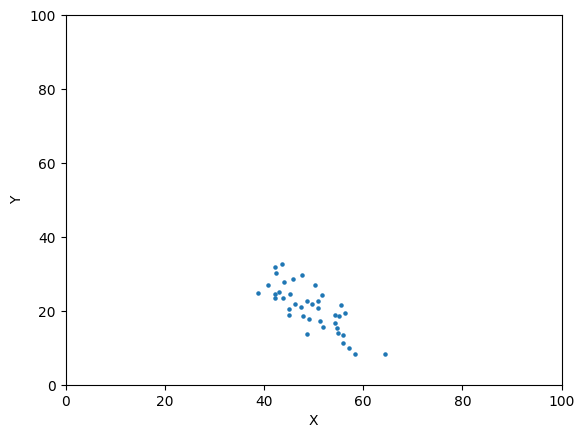

In [347]:
name = 'normal3'
normal3 = load(name)

plot_points(normal3)

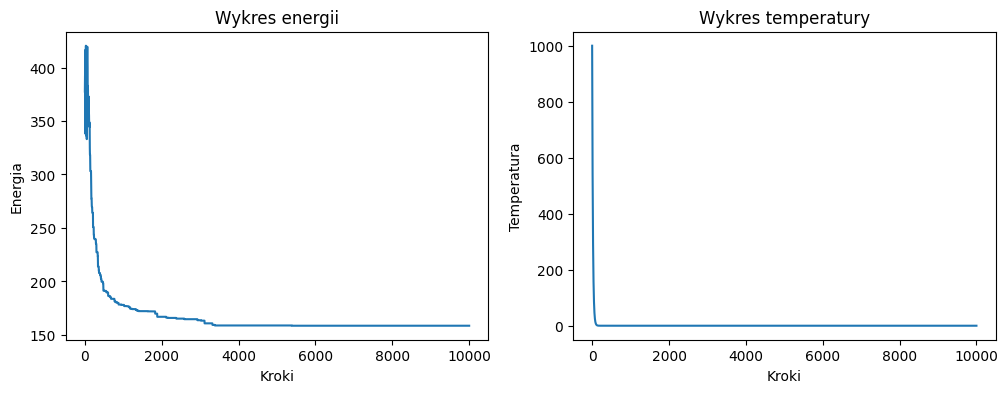

In [351]:
name = 'normal3'
normal3 = load(name)

cooling_function = exp_cooling
swap_function = arb_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(normal3, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

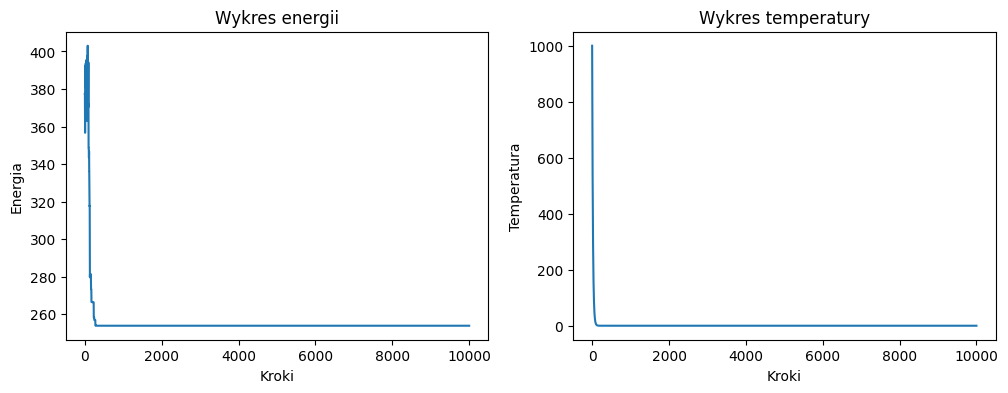

In [352]:
name = 'normal3'
normal3 = load(name)

cooling_function = exp_cooling
swap_function = cons_swap
start_temperature = 1000
epochs = 10000

energy, temperature, steps = simulated_annealing(normal3, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

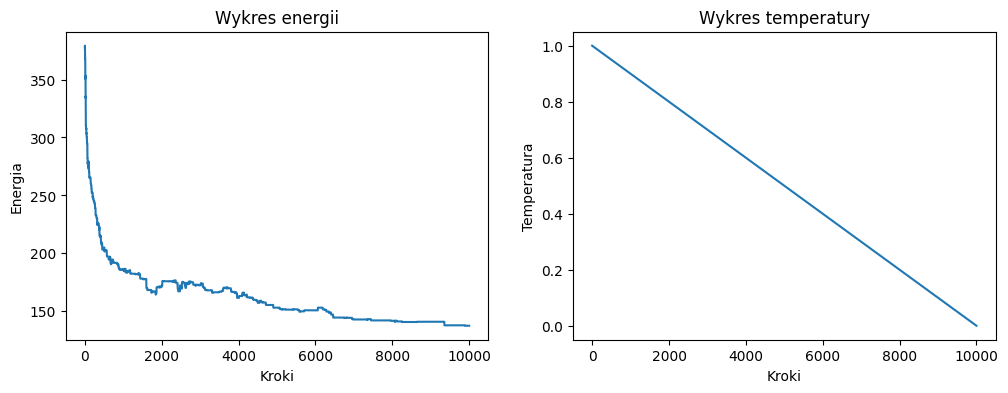

In [354]:
name = 'normal3'
normal3 = load(name)

cooling_function = lin_cooling
swap_function = arb_swap
start_temperature = 1
epochs = 10000

energy, temperature, steps = simulated_annealing(normal3, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

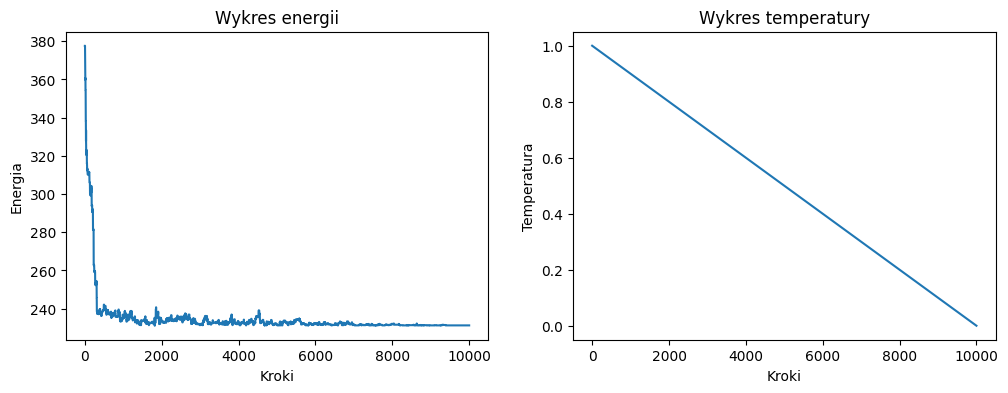

In [355]:
name = 'normal3'
normal3 = load(name)

cooling_function = lin_cooling
swap_function = cons_swap
start_temperature = 1
epochs = 10000

energy, temperature, steps = simulated_annealing(normal3, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

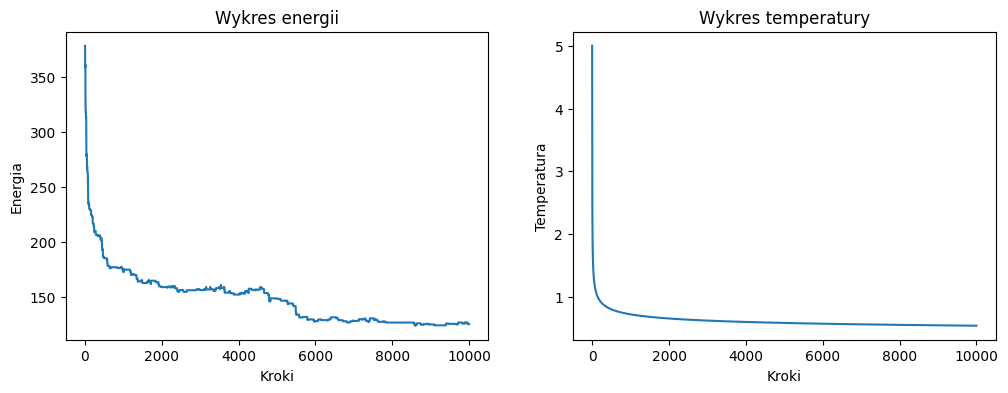

In [357]:
name = 'normal3'
normal3 = load(name)

cooling_function = log_cooling
swap_function = arb_swap
start_temperature = 5
epochs = 10000

energy, temperature, steps = simulated_annealing(normal3, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

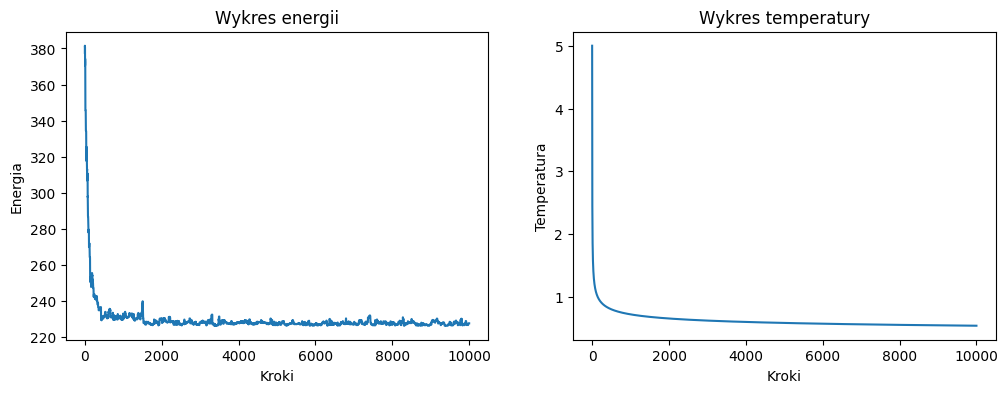

In [361]:
name = 'normal3'
normal3 = load(name)

cooling_function = log_cooling
swap_function = cons_swap
start_temperature = 5
epochs = 10000

energy, temperature, steps = simulated_annealing(normal3, epochs, start_temperature, swap_function, cooling_function)
plot_result(energy, temperature)

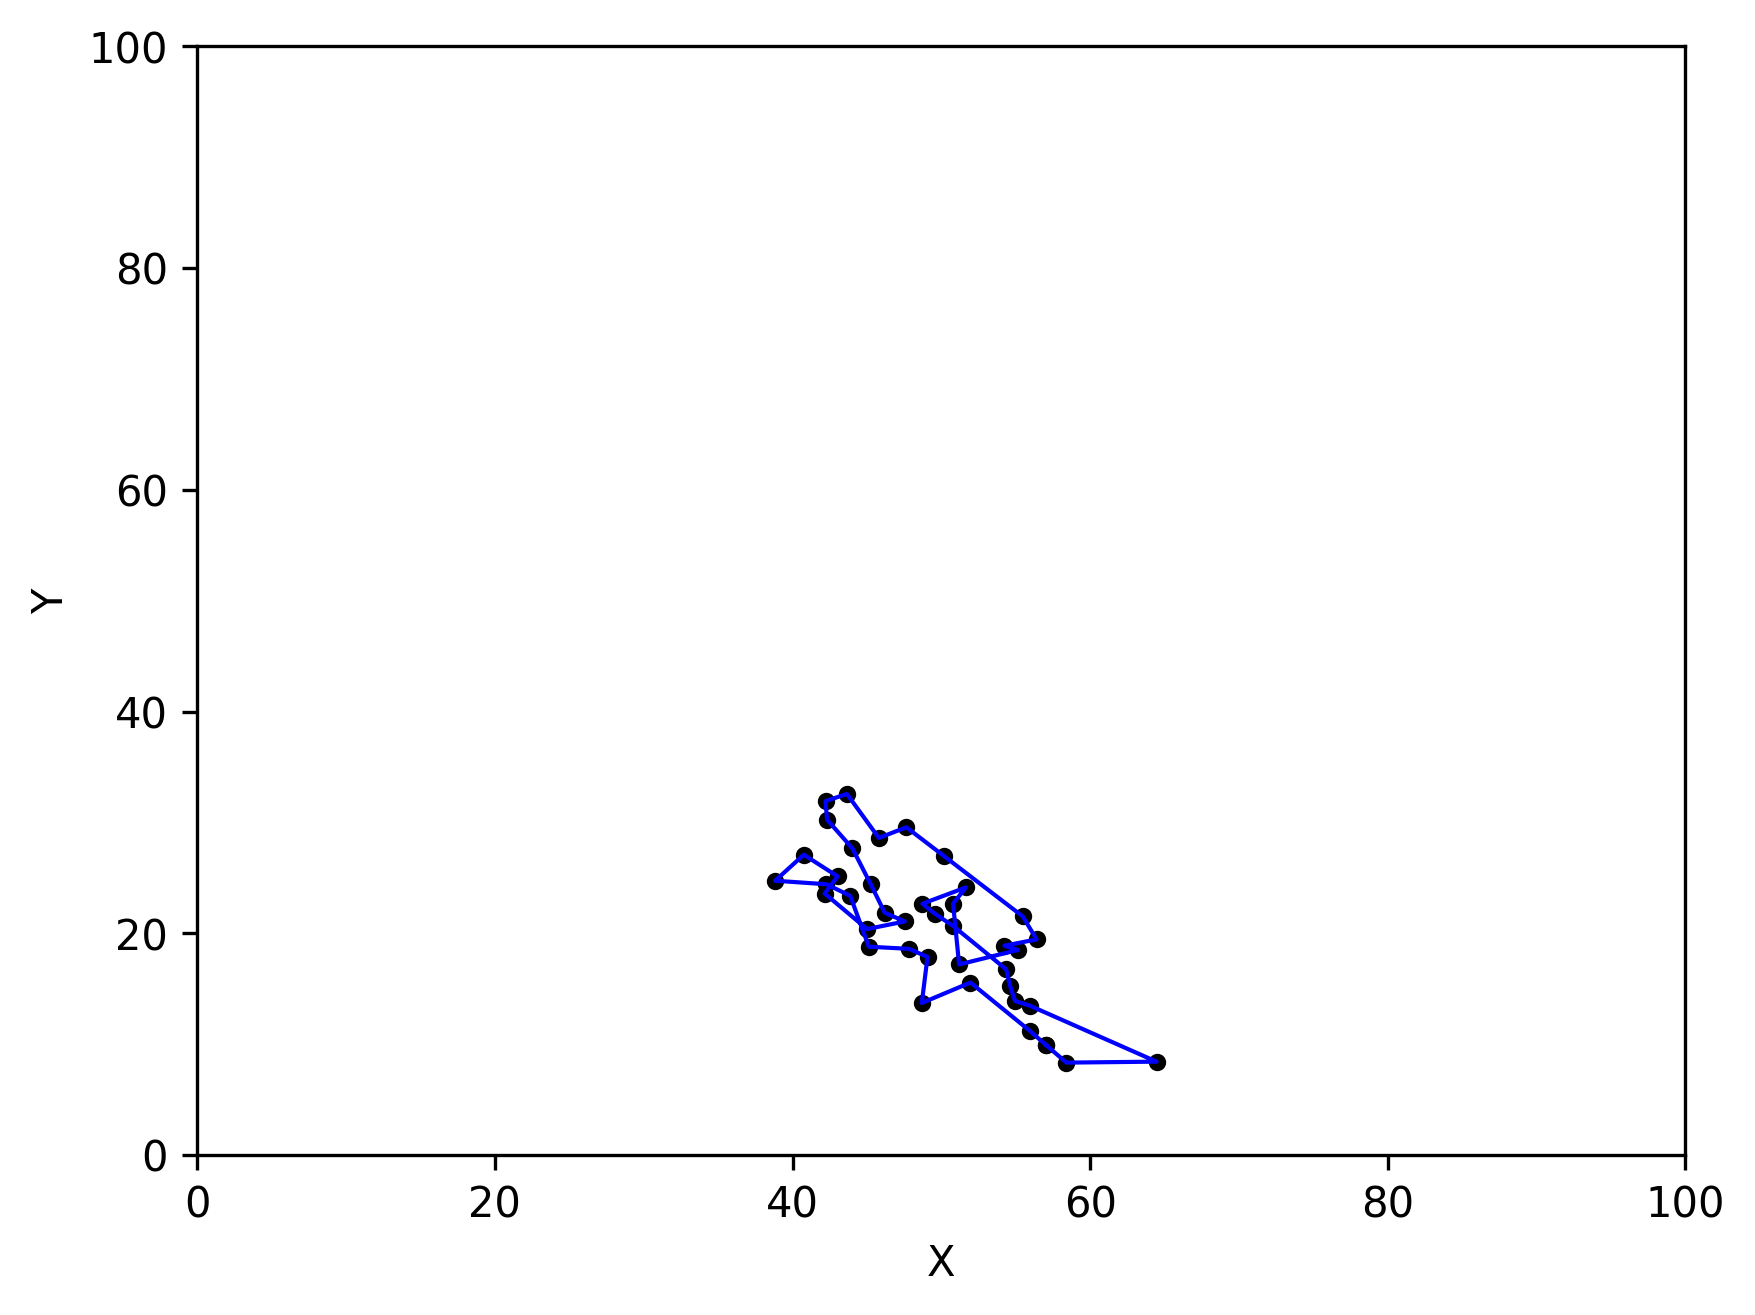

In [362]:
display_image('normal3.png')

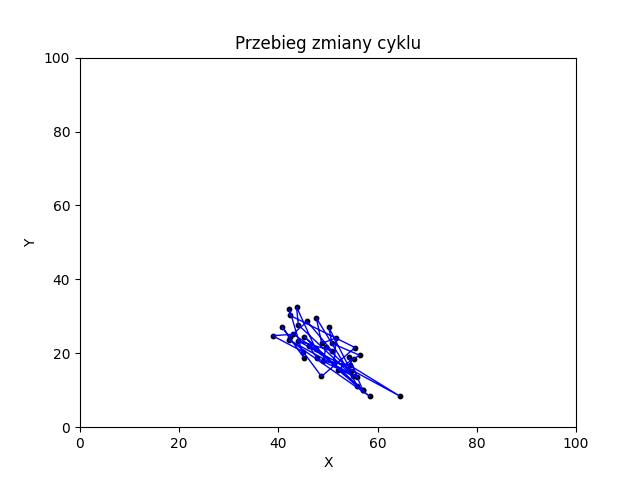

In [363]:
display_image('normal3.gif')

Arbitrary swap wypada znacznie lepiej od consecutive swap dla każdej funkcji temperatury. Wszystkie 3 funkcje temperatury wypadają podobnie, natomiast logarytmiczna i liniowa częściej uzyskują nieco lepsze wyniki od wykładniczej.